# Learning the seawater equation of state with ML

**The objective is to see if an MLP or a gradient-boosted tree can learn the seawater density ρ(SA, CT, p), and if it still gets the thermal expansion α and the haline contraction β right at depths outside the training range.**

Using CalCOFI bottle database, cleaned with `load_clean_calcofi.py`. Inputs used are: absolute salinity SA (g/kg), conservative temperature CT (°C) and pressure p (dbar). The ground truth is the TEOS-10 density from `gsw`.

For the models we used linear regression (baseline), MLP and LightGBM, based on lecture 6 of PHYS4811

**Structure**
- Part A: learn ρ with a random train/test split (interpolation)
- Part B: train on shallow water (p < 500 dbar), test on deeper water (extrapolation)
- Part C: compare the α and β of each model with the exact ones

In [44]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gsw
import tensorflow as tf
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.models import Model
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error
from lightgbm import LGBMRegressor

In [58]:
SEED = 67          
P_SPLIT = 500        # dbar
RHO_REF = 1025.0     
EPOCHS = 60         
BATCH_SIZE = 2048    

tf.keras.utils.set_random_seed(SEED)  
COLORS= {"Linear": "mediumorchid", "LightGBM": "blue", "MLP": "hotpink"}

## Data

In [46]:
df = pd.read_csv("calcofi_clean.csv")
print(df.shape)
assert not df.isna().any().any()      

features = ["p", "SA", "CT"]             
X = df[features].values
y = df["rho"].values - RHO_REF           
df[features + ["rho"]].describe()

(840484, 7)


,p,SA,CT,rho
count,840484.000000,840484.000000,840484.000000,840484.000000
mean,220.704093,34.000874,10.873402,1026.818966
std,305.561040,0.463185,4.231909,2.212579
min,-0.000000,30.253791,1.078091,1020.993723
25%,45.317875,33.646264,7.756669,1025.155715
50%,125.901884,34.021131,10.125232,1026.509455
75%,302.211597,34.359411,13.965660,1027.980659
max,5462.012245,37.209430,31.146621,1052.092828


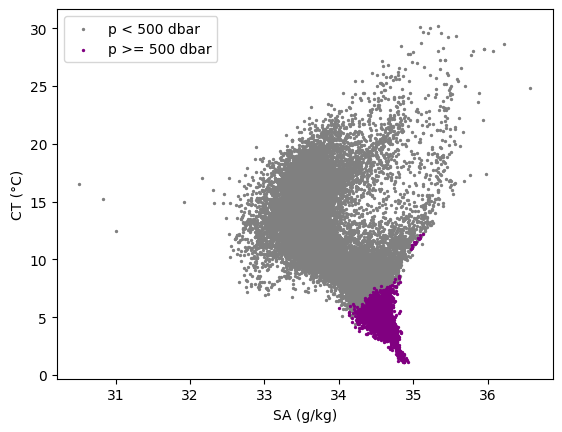

In [47]:
#little plot to visualize where the data sits in (SA,CT) space
sub = np.random.choice(len(df), size=min(30000, len(df)), replace=False)
deep_mask = df["p"].values[sub] >= P_SPLIT

fig, ax = plt.subplots()

ax.scatter(df["SA"].values[sub][~deep_mask], df["CT"].values[sub][~deep_mask],s=2,
           color="grey", label=f"p < {P_SPLIT} dbar")
ax.scatter(df["SA"].values[sub][deep_mask], df["CT"].values[sub][deep_mask], s=2,
           color="purple", label=f"p >= {P_SPLIT} dbar")

ax.set_xlabel("SA (g/kg)")
ax.set_ylabel("CT (°C)")
ax.legend()
plt.show()

# Helper functions

In [48]:
def rmse(a, b):
    return np.sqrt(mean_squared_error(a, b))


def rmse_table(p, y_true, preds, edges):
    rows = []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (p >= lo) & (p < hi)
        row = {"p range (dbar)": f"{lo:g} to {hi:g}", "n_samples": m.sum()}
        for name, pr in preds.items():
            row[name] = rmse(y_true[m], pr[m])
        rows.append(row)
    return pd.DataFrame(rows).set_index("p range (dbar)")
    

def binned_stat(p, values, edges, stat="mean", min_n=20):
    p_mid, value = [], []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (p >= lo) & (p < hi)
        if m.sum() >= min_n:
            p_mid.append((lo + hi) / 2)
            value.append(np.mean(values[m]) if stat == "mean" else np.median(values[m]))
    return pd.DataFrame({"p_mid": p_mid, "value": value})

# Part A: Intrapolation

In [49]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)

# Standardise
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)
y_mean, y_std = y_train.mean(), y_train.std()

# Linear regression
lin = LinearRegression()
lin.fit(X_train, y_train)

# LightGBM 
lgb = LGBMRegressor(n_estimators=300, learning_rate=0.05, num_leaves=31, random_state=SEED, verbose=-1)
lgb.fit(X_train, y_train)

# MLP 
inputs = Input(shape=(X_train.shape[1],))
x = Dense(64, activation="relu")(inputs)
x = Dense(64, activation="relu")(x)
outputs = Dense(1)(x)
mlp = Model(inputs, outputs)
mlp.compile(optimizer="adam", loss="mse")

history = mlp.fit(X_train_s, (y_train - y_mean) / y_std, validation_split=0.1,
                  epochs=EPOCHS, batch_size=BATCH_SIZE, verbose=0)

In [50]:
#prediction
pred_lin = lin.predict(X_test)
pred_lgb = lgb.predict(X_test)
pred_mlp = y_mean + y_std * mlp.predict(X_test_s, batch_size=8192, verbose=0).flatten()   # back to kg/m3

preds_A = {"Linear": pred_lin, "LightGBM": pred_lgb, "MLP": pred_mlp}

table_A = pd.DataFrame({
    "RMSE (kg/m3)": {n: rmse(y_test, pr) for n, pr in preds_A.items()},
    "MAE (kg/m3)": {n: mean_absolute_error(y_test, pr) for n, pr in preds_A.items()},
})
print(f"Baseline (predicting the mean): RMSE {y_test.std():.2f} kg/m3")
table_A

/Users/julietterenard/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/julietterenard/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/julietterenard/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_
/Users/julietterenard/Library/Python/3.9/lib/python/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


Baseline (predicting the mean): RMSE 2.22 kg/m3


,RMSE (kg/m3),MAE (kg/m3)
Linear,0.064873,0.042480
LightGBM,0.140236,0.029645
MLP,0.002742,0.001923


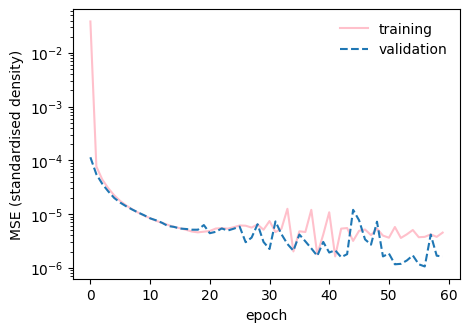

In [51]:
# MLP training curve (standardised density so the unit is std^2, not kg^2/m^6)
h = history.history
plt.figure(figsize=(5, 3.5))
plt.plot(h["loss"], label="training", color ="pink")
plt.plot(h["val_loss"], linestyle="--", label="validation")
plt.yscale("log"); plt.xlabel("epoch"); plt.ylabel("MSE (standardised density)")
plt.legend(frameon=False)
plt.show()

In [52]:
# RMSE by pressure range
edges_A = [0, 100, 200, 500, 1000, 2000, np.inf]
rmse_table(X_test[:, 0], y_test, preds_A, edges_A)

,n_samples,Linear,LightGBM,MLP
p range (dbar),,,,
0 to 100,71358,0.071700,0.058483,0.003466
100 to 200,32870,0.052255,0.027331,0.002443
200 to 500,42673,0.057593,0.019822,0.001596
500 to 1000,16768,0.062572,0.047332,0.001329
1000 to 2000,3622,0.043922,0.260049,0.002095
2000 to inf,806,0.213246,1.843074,0.008332


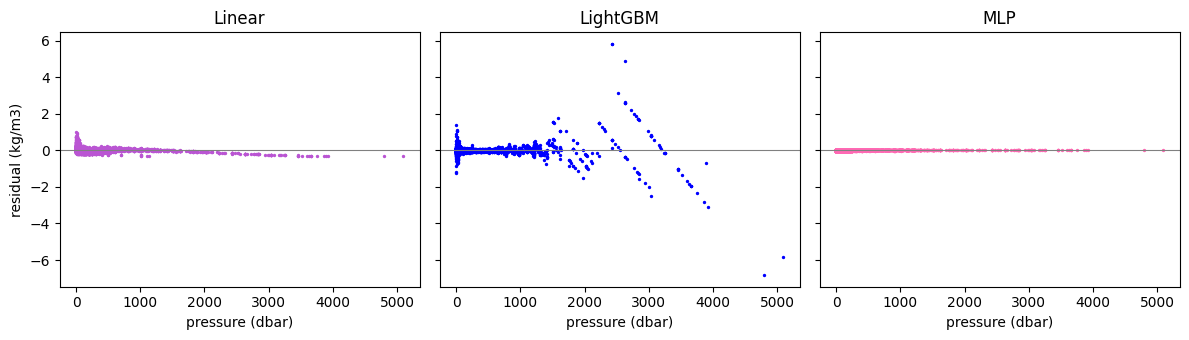

In [59]:
# Residuals against pressure on a random subsample of the test set
idx = np.random.choice(len(y_test), size=min(20000, len(y_test)), replace=False)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), sharey=True)
for ax, (name, pr) in zip(axes, preds_A.items()):
    ax.scatter(X_test[idx, 0], (pr - y_test)[idx], s=2, color= COLORS[name])
    ax.axhline(0, color="grey", linewidth=0.8)
    ax.set_title(name); ax.set_xlabel("pressure (dbar)")
axes[0].set_ylabel("residual (kg/m3)")
plt.tight_layout(); plt.show()

# Part B: extrapolation to greater depth

Train on shallow water only (p < 500 dbar) and test on deeper water (p >= 500 dbar). A random 20% of the shallow data is held out for comparison.


In [54]:
shallow = X[:, 0] < P_SPLIT
X_shallow, y_shallow = X[shallow], y[shallow]
X_deep, y_deep = X[~shallow], y[~shallow]
print(f"shallow (p < {P_SPLIT} dbar): {len(y_shallow)} samples,  deep (p >= {P_SPLIT} dbar): {len(y_deep)} samples")

X_train_B, X_test_in, y_train_B, y_test_in = train_test_split(X_shallow, y_shallow, test_size=0.2, random_state=SEED)

pd.DataFrame({"train min": X_train_B.min(axis=0), "train max": X_train_B.max(axis=0),
              "deep min": X_deep.min(axis=0), "deep max": X_deep.max(axis=0)}, index=features)

shallow (p < 500 dbar): 734560 samples,  deep (p >= 500 dbar): 105924 samples


,train min,train max,deep min,deep max
p,-0.000000,499.999304,500.001368,5462.012245
SA,30.326563,37.209430,33.586754,35.645604
CT,4.146472,31.146621,1.078091,12.779290


In [55]:
# Same steps as in Part A, on the shallow training data only
scaler_B = StandardScaler()
X_train_B_s = scaler_B.fit_transform(X_train_B)
y_mean_B, y_std_B = y_train_B.mean(), y_train_B.std()

#Linear
lin_B = LinearRegression()
lin_B.fit(X_train_B, y_train_B)

#LightGBM
lgb_B = LGBMRegressor(n_estimators=300, learning_rate=0.05, num_leaves=31, random_state=SEED)
lgb_B.fit(X_train_B, y_train_B)

#MLP
inputs = Input(shape=(X_train_B.shape[1],))
x = Dense(64, activation="relu")(inputs)
x = Dense(64, activation="relu")(x)
outputs = Dense(1)(x)
mlp_B = Model(inputs, outputs)
mlp_B.compile(optimizer="adam", loss="mse")

mlp_B.fit(X_train_B_s, (y_train_B - y_mean_B) / y_std_B, validation_split=0.1,
          epochs=EPOCHS, batch_size=BATCH_SIZE,verbose=0)


def predict_mlp_B(X):
    # raw inputs (p, SA, CT) in, density anomaly in kg/m3 out
    return y_mean_B + y_std_B * mlp_B.predict(scaler_B.transform(X), batch_size=8192, verbose=0).flatten()

In [56]:
# Evaluate on in-range test data then on the deep data
X_eval = np.vstack([X_test_in, X_deep])
y_eval = np.concatenate([y_test_in, y_deep])
preds_B = {"Linear": lin_B.predict(X_eval), "LightGBM": lgb_B.predict(X_eval), "MLP": predict_mlp_B(X_eval)}

edges_B = [0, 100, 200, P_SPLIT, 1000, 2000, np.inf]   # keep P_SPLIT btw 200 and 1000
rmse_table(X_eval[:, 0], y_eval, preds_B, edges_B)

/Users/julietterenard/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/julietterenard/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/julietterenard/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_
/Users/julietterenard/Library/Python/3.9/lib/python/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


,n_samples,Linear,LightGBM,MLP
p range (dbar),,,,
0 to 100,71368,0.064292,0.050841,0.003391
100 to 200,32821,0.053310,0.027446,0.002309
200 to 500,42723,0.056367,0.017317,0.002777
500 to 1000,84289,0.061432,1.004629,0.008266
1000 to 2000,17691,0.217475,3.762339,0.067601
2000 to inf,3944,0.947389,11.925742,0.264924


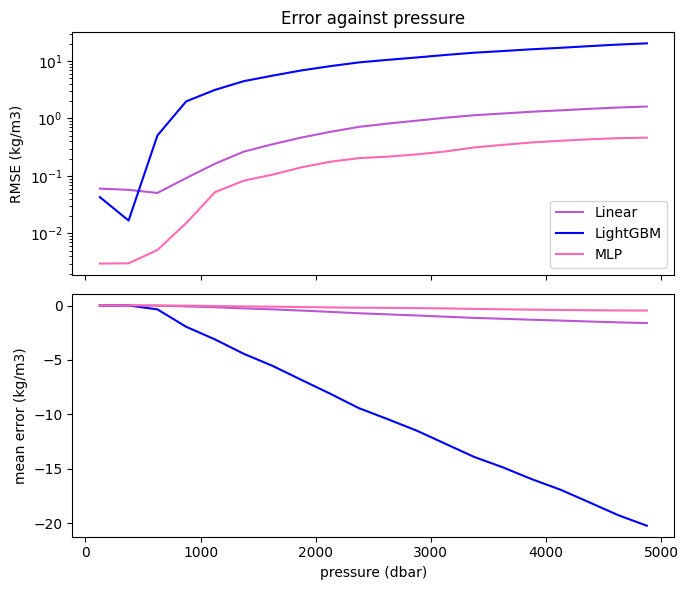

In [83]:
# error against pressure, in 250 dbar bins
edges_fine = np.arange(0, X_eval[:, 0].max() + 250, 250)
fig, axes = plt.subplots(2, 1, figsize=(7, 6), sharex=True)

for name, pr in preds_B.items():
    err = pr - y_eval
    rm = binned_stat(X_eval[:, 0], err ** 2, edges_fine, stat="mean")
    bi = binned_stat(X_eval[:, 0], err, edges_fine, stat="mean")
    axes[0].plot(rm["p_mid"], np.sqrt(rm["value"]), color=COLORS[name], label =name)
    axes[1].plot(bi["p_mid"], bi["value"], color = COLORS[name])
    
axes[0].set_yscale("log"); axes[0].set_ylabel("RMSE (kg/m3)")
axes[1].set_ylabel("mean error (kg/m3)"); axes[1].set_xlabel("pressure (dbar)")


axes[0].legend()
axes[0].set_title("Error against pressure")
plt.tight_layout()
plt.show()
#comment that the training range stops at P_split 

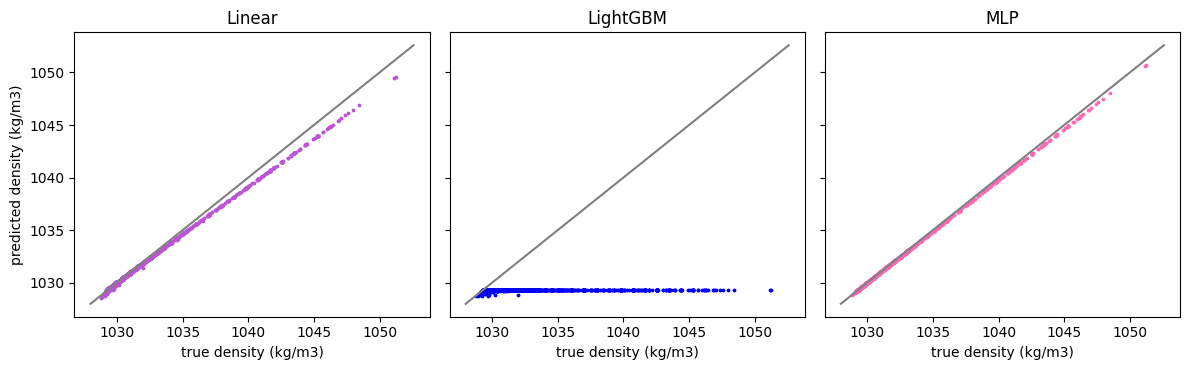

In [76]:
# Predicted against true density for the deep samples
idx = np.random.choice(len(y_deep), size=min(5000, len(y_deep)), replace=False)
fig, axes = plt.subplots(1, 3,figsize = (12,3.8), sharex=True, sharey=True)
lims = [y_deep.min() - 0.5, y_deep.max() + 0.5]
n_in = len(y_test_in)   
for ax, (name, pr) in zip(axes, preds_B.items()):
    pred_deep = pr[n_in:]
    ax.scatter(y_deep[idx] + RHO_REF, pred_deep[idx] + RHO_REF, s=3, color=COLORS[name])
    ax.plot(np.array(lims) + RHO_REF, np.array(lims) + RHO_REF, color="grey")
    ax.set_title(name); ax.set_xlabel("true density (kg/m3)")
axes[0].set_ylabel("predicted density (kg/m3)")

plt.tight_layout(); plt.show()

# Part C: Can the model recover the seawater equation? 

Thermal expansion α and haline contraction β
$$\alpha = -\frac{1}{\rho}\frac{\partial \rho}{\partial CT}\bigg|_{SA,\,p} \qquad\qquad \beta = \frac{1}{\rho}\frac{\partial \rho}{\partial SA}\bigg|_{CT,\,p}$$

These are the definitions used by `gsw.alpha` and `gsw.beta`, which give the exact values.
How the derivatives of each model are obtained:
- **MLP:** automatic differentiation (backpropagation with respect to the inputs).
- **Linear regression and LightGBM:** finite differences, $\partial\rho/\partial x \approx [\rho(x+h)-\rho(x-h)]/2h$. A tree model is piecewise constant, so its derivative only makes sense over a finite step h.

The models in this part are the ones trained on shallow water in Part B. Pressure is held fixed in both derivatives, so we never differentiate with respect to p.

In [84]:
def alpha_beta(X, d_rho_dSA, d_rho_dCT):
    # Turn density derivatives into alpha and beta. We divide by the true density so only the derivative can be wrong
    rho = gsw.rho(X[:, 1], X[:, 2], X[:, 0])
    return -d_rho_dCT / rho, d_rho_dSA / rho


def true_coeffs(X):
    return gsw.alpha(X[:, 1], X[:, 2], X[:, 0]), gsw.beta(X[:, 1], X[:, 2], X[:, 0])


def fd_coeffs(predict, X, h_SA, h_CT):
    # FLAG: central finite differences. predict takes unscaled inputs and returns density in kg/m3.
    X_hi, X_lo = X.copy(), X.copy()
    X_hi[:, 2] += h_CT; X_lo[:, 2] -= h_CT
    d_rho_dCT = (predict(X_hi) - predict(X_lo)) / (2 * h_CT)
    X_hi, X_lo = X.copy(), X.copy()
    X_hi[:, 1] += h_SA; X_lo[:, 1] -= h_SA
    d_rho_dSA = (predict(X_hi) - predict(X_lo)) / (2 * h_SA)
    return alpha_beta(X, d_rho_dSA, d_rho_dCT)


def mlp_coeffs(mlp, scaler, y_std, X):
    # FLAG: automatic differentiation of the MLP with tf.GradientTape.
    x_std = tf.convert_to_tensor(scaler.transform(X), dtype=tf.float32)
    with tf.GradientTape() as tape:
        tape.watch(x_std)                       # we want gradients with respect to the inputs, not the weights
        out = mlp(x_std, training=False)   # standardised density, one value per sample
    grad_std = tape.gradient(out, x_std).numpy()   # d(out)/d(x_std), shape (n_samples, 3). Each sample only depends on its own row.
    # FLAG: chain rule back to physical units. rho = y_mean + y_std * out and x_std = (x - mean) / scale, so
    # d(rho)/dx = y_std * d(out)/d(x_std) / scale
    d_rho_dx = y_std * grad_std / scaler.scale_
    return alpha_beta(X, d_rho_dx[:, 1], d_rho_dx[:, 2])


# Finite-difference steps. FLAG: these are choices, not physics. If h is much smaller than the spacing between
# the splits of a tree, the tree gives 0 for the derivative. Try other values and see how LightGBM changes.
H_SA, H_CT = 0.1, 0.5     # g/kg and °C

In [85]:
# Test 1: the finite-difference code applied to the EXACT density must give the exact alpha and beta.
# This checks the formulas and the size of the finite-difference error itself, using the same steps as below.
def exact_density(X):
    return gsw.rho(X[:, 1], X[:, 2], X[:, 0]) - RHO_REF

X_chk = X_eval[::20]
a_fd, b_fd = fd_coeffs(exact_density, X_chk, H_SA, H_CT)
a_ex, b_ex = true_coeffs(X_chk)
print("max relative error of alpha from the finite-difference code on the exact formula: %.2e" % np.max(np.abs(a_fd / a_ex - 1)))
print("max relative error of beta  from the finite-difference code on the exact formula: %.2e" % np.max(np.abs(b_fd / b_ex - 1)))

max relative error of alpha from the finite-difference code on the exact formula: 1.16e-04
max relative error of beta  from the finite-difference code on the exact formula: 1.08e-08


In [88]:
# Samples used to compare the coefficients: a random subset of the in-range test set plus a random subset of the deep set
N_DER = 20000
X_der = np.vstack([X_test_in[np.random.choice(len(X_test_in), size=min(N_DER, len(X_test_in)), replace=False)],
                   X_deep[np.random.choice(len(X_deep), size=min(N_DER, len(X_deep)), replace=False)]])
alpha_true, beta_true = true_coeffs(X_der)

coef = {"Linear":   fd_coeffs(lin_B.predict, X_der, H_SA, H_CT),
        "LightGBM": fd_coeffs(lgb_B.predict, X_der, H_SA, H_CT),
        "MLP":      mlp_coeffs(mlp_B, scaler_B, y_std_B, X_der)}

# Test 2: for the MLP, automatic differentiation and a small finite difference must agree closely.
# Tiny differences remain because a ReLU network is piecewise linear: a finite step can cross a kink, autodiff cannot.
sel = slice(None, None, 10)
a_ad, b_ad = coef["MLP"][0][sel], coef["MLP"][1][sel]
a_fd, b_fd = fd_coeffs(predict_mlp_B, X_der[sel], 0.01, 0.01)
print("MLP, median |autodiff - finite difference| / |finite difference|:  alpha %.1e,  beta %.1e"
      % (np.median(np.abs(a_ad - a_fd) / np.abs(a_fd)), np.median(np.abs(b_ad - b_fd) / np.abs(b_fd))))

/Users/julietterenard/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/julietterenard/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/julietterenard/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_
/Users/julietterenard/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/julietterenard/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/julietterenard/Library/Python/3.9/lib/python/site-p

MLP, median |autodiff - finite difference| / |finite difference|:  alpha 3.7e-05,  beta 1.8e-05


In [89]:
# Median absolute relative error of alpha and beta (in %) by pressure range
alpha_pred = {n: c[0] for n, c in coef.items()}
beta_pred = {n: c[1] for n, c in coef.items()}

def rel_err_table(p, true, preds, edges):
    # Same idea as rmse_table, but with the median |relative error| in %
    rows = []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (p >= lo) & (p < hi)
        if m.sum() == 0:
            continue
        row = {"p range (dbar)": f"{lo:g} to {hi:g}", "n_samples": m.sum()}
        for name, pr in preds.items():
            row[name] = np.median(np.abs(pr[m] - true[m]) / np.abs(true[m]) * 100)
        rows.append(row)
    return pd.DataFrame(rows).set_index("p range (dbar)")

print("alpha: median |relative error| (%)")
display(rel_err_table(X_der[:, 0], alpha_true, alpha_pred, edges_B))
print("beta: median |relative error| (%)")
display(rel_err_table(X_der[:, 0], beta_true, beta_pred, edges_B))

alpha: median |relative error| (%)


,n_samples,Linear,LightGBM,MLP
p range (dbar),,,,
0 to 100,9766,9.327841,7.815370,1.586001
100 to 200,4474,26.510245,10.586940,2.022948
200 to 500,5760,40.760592,12.538984,1.563970
500 to 1000,15929,58.360192,72.692562,3.514217
1000 to 2000,3331,66.535223,100.000000,10.312368
2000 to inf,740,41.598778,100.000000,2.727242


beta: median |relative error| (%)


,n_samples,Linear,LightGBM,MLP
p range (dbar),,,,
0 to 100,9766,5.585740,10.434303,2.126037
100 to 200,4474,6.887029,12.760572,2.408182
200 to 500,5760,7.410019,14.137601,0.932403
500 to 1000,15929,7.870037,56.343498,2.319366
1000 to 2000,3331,7.983093,82.823413,6.210580
2000 to inf,740,7.059015,88.869443,9.503417


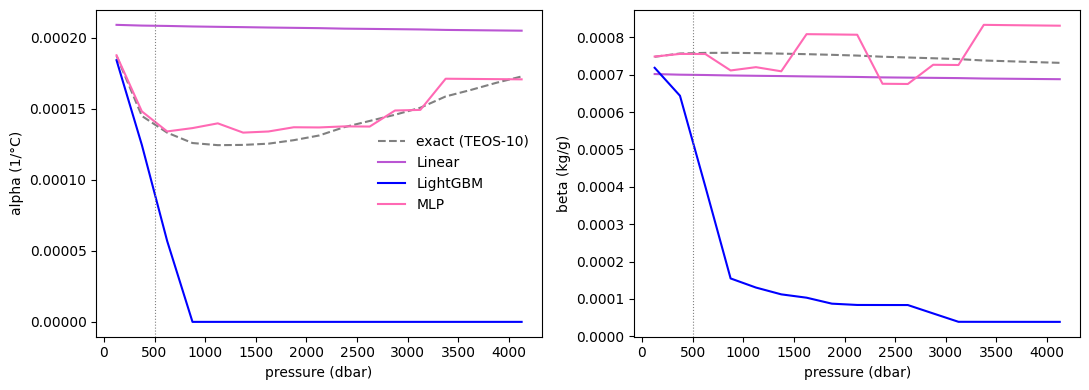

In [91]:
# alpha and beta against pressure: median in each 250 dbar bin, exact values vs each model
edges_der = np.arange(0, X_der[:, 0].max() + 250, 250)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, true, preds, label in [(axes[0], alpha_true, alpha_pred, "alpha (1/°C)"),
                               (axes[1], beta_true, beta_pred, "beta (kg/g)")]:
    t = binned_stat(X_der[:, 0], true, edges_der, stat="median")
    ax.plot(t["p_mid"], t["value"], color="grey", linestyle="--", label="exact (TEOS-10)")
    for name, pr in preds.items():
        m = binned_stat(X_der[:, 0], pr, edges_der, stat="median")
        ax.plot(m["p_mid"], m["value"], color=COLORS[name], label=name)
    ax.axvline(P_SPLIT, color="grey", linestyle=":", linewidth=0.8)
    ax.set_xlabel("pressure (dbar)"); ax.set_ylabel(label)
axes[0].legend(frameon=False, loc="center right")
plt.tight_layout(); plt.show()

## Results and answer to the research question

*To fill in after running the notebook. Suggested points:*

1. **Part A (interpolation).** Which model has the smallest RMSE, and is it small compared with the density range?
2. **Part B (extrapolation).** How does each model's error grow with pressure beyond 500 dbar? Which one fails first, and how (constant bias for LightGBM, drifting trend for the linear model and the MLP)? Remember the caveat about SA and CT also being out of range.
3. **Part C (physics).** Does each model recover α and β in range? Beyond 500 dbar, does the pressure dependence of α (the thermobaric effect) appear in any model?
4. **Answer.** One or two sentences that answer the research question directly, including why the extrapolation behaviour of trees and neural networks differs.